# RDKit molecular descriptors and preparing molecule data

Companion notebook for the narrated video. The default collection and all recorded values use **RDKit 2026.09.1**. The analysis uses all **642 FreeSolv v0.52 molecules**, at the fixed source revision below. The `label` column is experimental gas-to-water hydration free energy in **kcal/mol** and is kept separate from descriptor inputs.

FreeSolv data: David L. Mobley, J. Peter Guthrie, and contributors; **CC BY 4.0**. [Repository and attribution](https://github.com/MobleyLab/FreeSolv) · [Data license](https://github.com/MobleyLab/FreeSolv/blob/master/LICENSE).

Run the cells in order. This is a full-dataset preprocessing demonstration. For model evaluation, split first and learn imputation and selection only on the training set, then reuse those fitted transformations on validation and test data.


## 1. Install and import

Run in your terminal (or replace `python -m pip` with `%pip` in a notebook cell):
```bash
python -m pip install rdkit==2026.9.1
python -m pip install pandas numpy matplotlib
```
The executed notebook also records dependency versions below. The supplied source file is used when present, with its SHA-256 checked; otherwise the same fixed URL is loaded.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors

Matplotlib is building the font cache; this may take a moment.


In [2]:
print("RDKit:", rdBase.rdkitVersion)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
assert rdBase.rdkitVersion == "2026.09.1", "Use the pinned RDKit version."

RDKit: 2026.09.1
pandas: 3.1.0
NumPy: 2.5.4


## 2. One molecule
`MolFromSmiles` creates a molecular graph. Hydrogens may be implicit in the SMILES, but molecular mass includes them.

In [3]:
mol = Chem.MolFromSmiles("CCO")
print(f"Molecular weight: {Descriptors.MolWt(mol)}")
print(f"#Hydrogen Donors: {Descriptors.NumHDonors(mol)}")
print(f"TPSA: {Descriptors.TPSA(mol)}")

Molecular weight: 46.069
#Hydrogen Donors: 1
TPSA: 20.23


In [4]:
values = Descriptors.CalcMolDescriptors(
    mol, missingVal=float("nan")
)
print(rdBase.rdkitVersion, len(values))

2026.09.1 217


In [5]:
preview_names = ["MolWt", "ExactMolWt", "HeavyAtomCount", "NumHDonors",
                 "TPSA", "MolLogP", "FractionCSP3", "fr_benzene"]
{name: values[name] for name in preview_names}

{'MolWt': 46.069,
 'ExactMolWt': 46.041864812,
 'HeavyAtomCount': 3,
 'NumHDonors': 1,
 'TPSA': 20.23,
 'MolLogP': -0.0014000000000000123,
 'FractionCSP3': 1.0,
 'fr_benzene': 0}

## 3. Load and validate FreeSolv
Use `skiprows=3` to skip the three header lines. Do **not** use `comment="#"`, because `#` also denotes triple bonds inside SMILES. The fixed URL locks the data revision.

In [6]:
url = (
    "https://raw.githubusercontent.com/MobleyLab/FreeSolv/"
    "134cd763f95d54d818fc0618095aa01cbe470fc3/database.txt"
)
from pathlib import Path
import hashlib
local_candidates = [Path("../data/freesolv_v0.52_database.txt"),
                    Path("animations/RDKit_Descriptors/data/freesolv_v0.52_database.txt")]
local_source = next((p for p in local_candidates if p.exists()), None)
if local_source is not None:
    expected_sha256 = "2d13f095713bc39b85f85dd7b4e5483fbb12fc694bf253bb1d92a4c4d484f260"
    assert hashlib.sha256(local_source.read_bytes()).hexdigest() == expected_sha256
source = local_source if local_source is not None else url
data = pd.read_csv(
    source, sep=";", skiprows=3, header=None,
    usecols=[0, 1, 3], names=["id", "smiles", "label"]
)
data["id"] = data["id"].str.strip()
data["smiles"] = data["smiles"].fillna("").str.strip()
data.head()

,id,smiles,label
0,mobley_1017962,CCCCCC(=O)OC,-2.49
1,mobley_1019269,CCCCO,-4.72
2,mobley_1034539,c1cc(c(cc1c2cc(c(c(c2Cl)Cl)Cl)Cl)Cl)Cl,-3.04
3,mobley_1036761,C1CCC(CC1)N,-4.59
4,mobley_1046331,c1ccc(cc1)OC=O,-3.82


In [7]:
data["mol"] = data["smiles"].map(Chem.MolFromSmiles)
print(f"Number of molecules before data cleaning: {len(data)}")
valid = [
    mol is not None and mol.GetNumAtoms() > 0
    for mol in data["mol"]
]
data = data.loc[valid].copy()
print(f"Number of molecules after data cleaning: {len(data)}")

Number of molecules before data cleaning: 642
Number of molecules after data cleaning: 642


In [8]:
data["canonical"] = data["mol"].map(Chem.MolToSmiles)
print("Duplicate structures:", data["canonical"].duplicated().sum())
data = data.drop_duplicates("canonical").copy()

Duplicate structures: 0


The example dataset has no duplicate canonical structures. For repeated measurements in another dataset, examine their labels before deciding whether to keep, average, or remove measurements. Canonicalization alone does not standardize salts, tautomers, or protonation states.

In [9]:
# Separate illustration: these are the same molecular graph.
[Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in ["CCO", "OCC"]]

['CCO', 'CCO']

In [10]:
def calculate_descriptors(frame):
    rows = [
        Descriptors.CalcMolDescriptors(mol, missingVal=np.nan)
        for mol in frame["mol"]
    ]
    return pd.DataFrame(rows, index=frame.index).replace(
        [np.inf, -np.inf], np.nan
    )

X_raw = calculate_descriptors(data)
print(X_raw.shape)

(642, 217)


In [11]:
X_raw.loc[:, preview_names].head()

,MolWt,ExactMolWt,HeavyAtomCount,NumHDonors,TPSA,MolLogP,FractionCSP3,fr_benzene
0,130.187,130.099380,9,0,26.30,1.7397,0.857143,0
1,74.123,74.073165,5,1,20.23,0.7788,1.000000,0
2,360.882,357.844416,18,0,0.00,7.2740,0.000000,2
3,99.177,99.104799,7,1,26.02,1.2778,1.000000,0
4,122.123,122.036779,9,0,26.30,1.2218,0.000000,1


## 4. Descriptor distributions
These plots use raw descriptor values from the complete dataset, before imputation. Histograms use 20 equal-width bins over the complete observed range. The count descriptor uses integer bars. This section supplies the plots used earlier in the video.

In [12]:
plot_directory = Path("plots")
plot_directory.mkdir(exist_ok=True)
plt.style.use("dark_background")
plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (8, 5)})

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(plot_directory / f"{name}.png", dpi=180, transparent=True)
    fig.savefig(plot_directory / f"{name}.svg", transparent=True)
    plt.show()

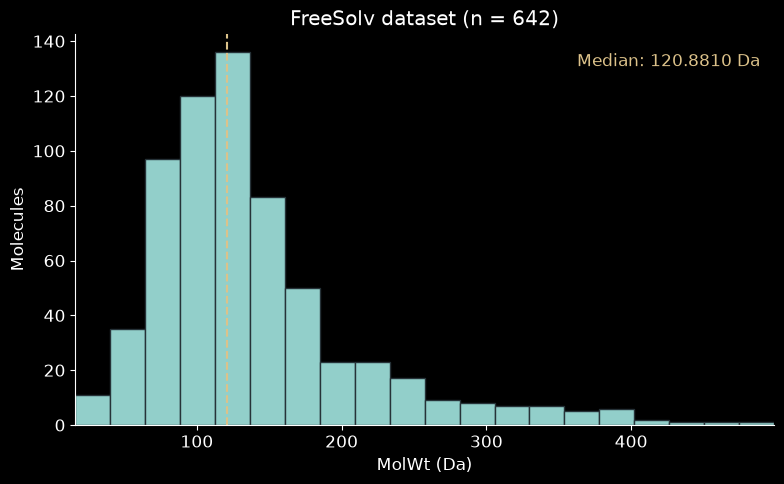

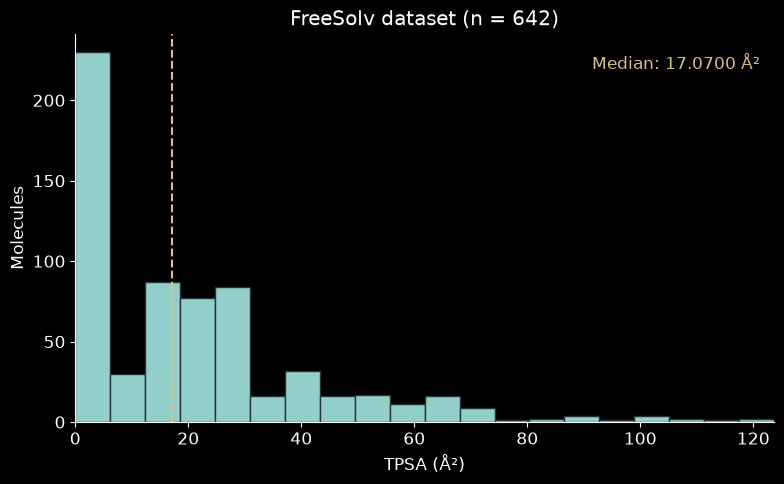

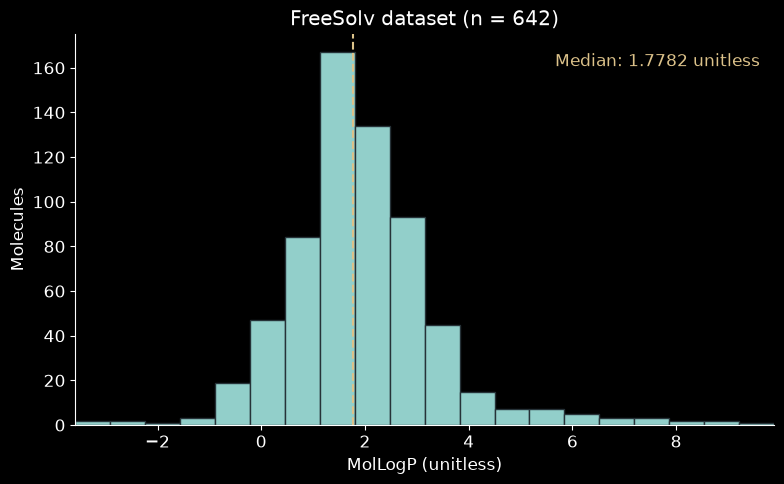

In [13]:
for name, unit in [
    ("MolWt", "Da"), ("TPSA", "Å²"), ("MolLogP", "unitless")
]:
    plot_values = X_raw[name].dropna()
    fig, ax = plt.subplots()
    ax.hist(plot_values, bins=20, color="#92cfca", edgecolor="#263238")
    median = plot_values.median()
    ax.axvline(median, linestyle="--", color="#dcc28a")
    ax.text(0.98, 0.95, f"Median: {median:.4f} {unit}",
            transform=ax.transAxes, ha="right", va="top", color="#dcc28a")
    ax.set_xlim(plot_values.min(), plot_values.max())
    ax.set(title=f"FreeSolv dataset (n = {len(plot_values)})",
           xlabel=f"{name} ({unit})", ylabel="Molecules")
    save_plot(fig, name)

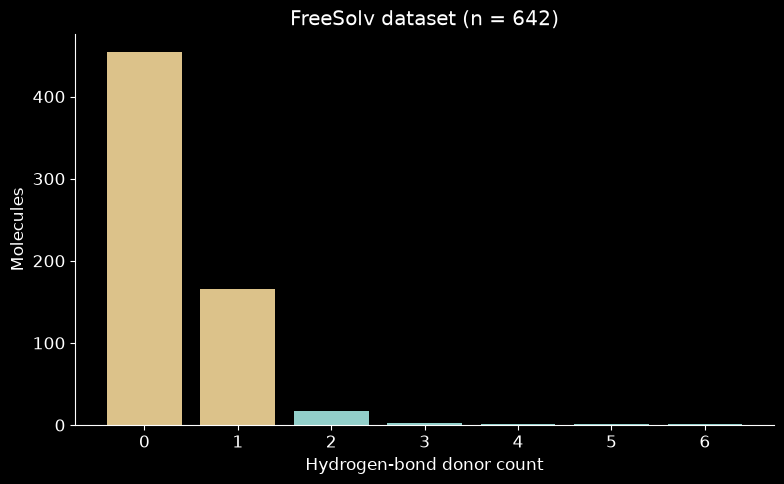

{0: 454, 1: 166, 2: 17, 3: 2, 4: 1, 5: 1, 6: 1}


In [14]:
counts = X_raw["NumHDonors"].value_counts()
maximum = int(X_raw["NumHDonors"].max())
counts = counts.reindex(range(maximum + 1), fill_value=0)
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values,
       color=["#dcc28a" if i < 2 else "#92cfca" for i in counts.index])
ax.set_xticks(counts.index)
ax.set(title="FreeSolv dataset (n = 642)",
       xlabel="Hydrogen-bond donor count", ylabel="Molecules")
save_plot(fig, "NumHDonors")
print(counts.to_dict())

## 5. Missing values and constant descriptors
A valid molecular graph does not guarantee every descriptor can be calculated. The sodium example below is separate from FreeSolv. `BCUT2D_MWHI` is the largest eigenvalue of the atomic-mass-weighted BCUT matrix; RDKit's default BCUT implementation also evaluates atom charge, logP, and refractivity parameterizations. Missing parameters for sodium make the default calculation unavailable.

`missingVal` handles a descriptor that raises an exception. An implementation may also return NaN directly; infinite values were normalized to NaN above. A valid zero, such as benzene's donor count, is not missing.

In [15]:
sodium = Chem.MolFromSmiles("[Na+]")
sodium_values = Descriptors.CalcMolDescriptors(sodium, missingVal=np.nan)
print("Sodium molecule valid:", sodium is not None)
print("MolWt:", sodium_values["MolWt"])
print("BCUT2D_MWHI:", sodium_values["BCUT2D_MWHI"])
print("Benzene NumHDonors:", Descriptors.NumHDonors(Chem.MolFromSmiles("c1ccccc1")))

Sodium molecule valid: True
MolWt: 22.99
BCUT2D_MWHI: nan
Benzene NumHDonors: 0


In [16]:
print("Missing:", X_raw.isna().sum().sum())

Missing: 0


Median replacement is a simple baseline and does not recover the true chemical value. Investigate substantial missingness. This full-dataset demonstration initializes `X` before using it, correcting the ordering omission in the draft transcript. An entirely missing column has no median and will be excluded by the nonconstant-column rule below.

In [17]:
X = X_raw.copy()
medians = X.median()
X = X.fillna(medians)

In [18]:
usable = X_raw.columns[
    X_raw.nunique(dropna=True) > 1
]
X = X[usable].copy()
print("Removed before correlation:", X_raw.shape[1] - len(usable))
print("Variable columns:", len(usable))

Removed before correlation: 32
Variable columns: 185


The selection mask is computed from `X_raw`, then applied to the imputed `X`. This preserves any imputation instead of resetting `X` to raw values. FreeSolv has no missing values, so the numerical outputs remain identical to the transcript.

## 6. Recognizing redundant descriptors
MolWt uses average atomic masses for unspecified isotopes. ExactMolWt uses the most abundant isotope masses where isotopes are unspecified. The second pair has identical values in this dataset; this is not a universal equivalence of the definitions.

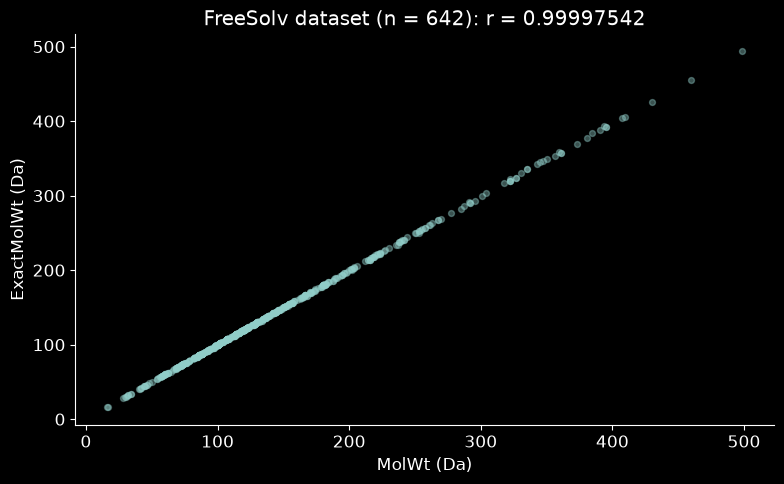

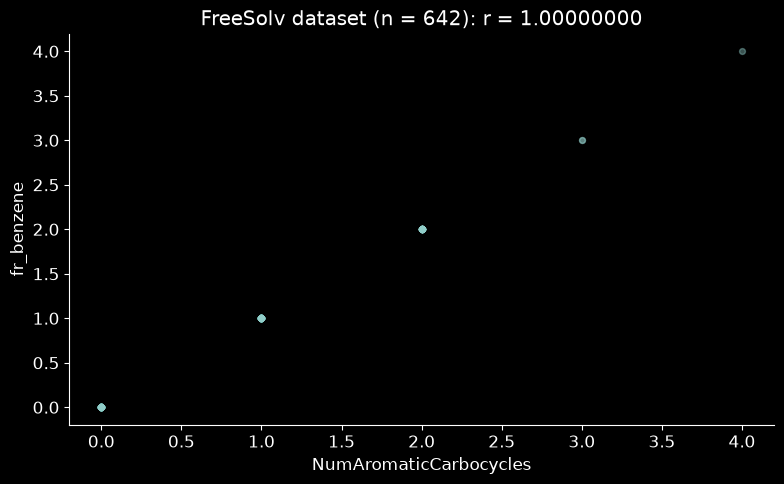

In [19]:
for first, second in [
    ("MolWt", "ExactMolWt"),
    ("NumAromaticCarbocycles", "fr_benzene")
]:
    fig, ax = plt.subplots()
    ax.scatter(X_raw[first], X_raw[second], alpha=0.4, s=18, color="#92cfca")
    r = X_raw[first].corr(X_raw[second])
    unit = " (Da)" if first == "MolWt" else ""
    ax.set(xlabel=first + unit, ylabel=second + unit,
           title=f"FreeSolv dataset (n = 642): r = {r:.8f}")
    save_plot(fig, first + "__" + second)

## 7. Remove correlated descriptors in deterministic order
Greedily retain each descriptor only if its unrounded absolute Pearson correlation with every already retained descriptor is at most 0.95. Column order determines which member survives. This is one transparent demonstration rule, not a guarantee that retained descriptors are statistically independent.

In [20]:
correlation = X.corr().abs()
keep = []
for name in X.columns:
    if not (correlation.loc[name, keep] > 0.95).any():
        keep.append(name)

In [21]:
removed = X.shape[1] - len(keep)
X = X[keep]
print("Removed by correlation:", removed)
print("Descriptors left:", len(keep))

Removed by correlation: 28
Descriptors left: 157


In [22]:
assert X_raw.shape == (642, 217)
assert X_raw.isna().sum().sum() == 0
assert len(usable) == 185 and removed == 28 and len(keep) == 157
assert X.index.equals(data.index)
assert {"MolWt", "NumAromaticCarbocycles"}.issubset(keep)
assert "ExactMolWt" not in keep and "fr_benzene" not in keep
retained_correlation = X.corr().abs().to_numpy()
pair_values = retained_correlation[np.triu_indices(len(keep), k=1)]
assert np.isfinite(pair_values).all() and pair_values.max() <= 0.95
assert counts.tolist() == [454, 166, 17, 2, 1, 1, 1]
print("Verified: 217 → 185 → 157; no retained pair exceeds abs(r) = 0.95.")
print("Maximum retained absolute correlation:", pair_values.max())

Verified: 217 → 185 → 157; no retained pair exceeds abs(r) = 0.95.
Maximum retained absolute correlation: 0.9460315124496745


In [23]:
output = data[["id", "smiles", "label"]].join(X)
output.to_csv("freesolv_descriptors.csv", index=False)
print("Exported:", output.shape)
output.head()

Exported: (642, 160)


,id,smiles,label,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,NumValenceElectrons,...,fr_piperdine,fr_piperzine,fr_priamide,fr_pyridine,fr_sulfide,fr_sulfone,fr_term_acetylene,fr_thiophene,fr_unbrch_alkane,fr_urea
0,mobley_1017962,CCCCCC(=O)OC,-2.49,10.464402,0.094028,-0.094028,0.427720,9.111111,130.187,54,...,0,0,0,0,0,0,0,0,2,0
1,mobley_1019269,CCCCO,-4.72,8.066250,0.343750,0.343750,0.512822,8.400000,74.123,32,...,0,0,0,0,0,0,0,0,1,0
2,mobley_1034539,c1cc(c(cc1c2cc(c(c(c2Cl)Cl)Cl)Cl)Cl)Cl,-3.04,6.146029,0.214728,0.214728,0.370115,10.777778,360.882,94,...,0,0,0,0,0,0,0,0,0,0
3,mobley_1036761,C1CCC(CC1)N,-4.59,5.634722,0.535880,0.535880,0.486084,25.285714,99.177,42,...,0,0,0,0,0,0,0,0,0,0
4,mobley_1046331,c1ccc(cc1)OC=O,-3.82,9.752041,0.412037,0.412037,0.551119,8.444444,122.123,46,...,0,0,0,0,0,0,0,0,0,0


## References and scientific scope
- [RDKit descriptor API](https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html): scalar descriptor collection and missing values.
- [RDKit TPSA implementation](https://www.rdkit.org/docs/RDKit_Book.html#implementation-of-the-tpsa-descriptor): nitrogen and oxygen contributions by default.
- [Wildman–Crippen LogP](https://rdkit.org/docs/source/rdkit.Chem.Crippen.html): atom-contribution property estimate.
- [BCUT API](https://www.rdkit.org/docs/source/rdkit.Chem.rdMolDescriptors.html): atom-property weights and eigenvalue ordering.
- [ChemBERTa-2](https://arxiv.org/abs/2209.01712): the multi-task regression pretraining variant predicts 200 RDKit-derived properties.
- [Fixed FreeSolv data](https://raw.githubusercontent.com/MobleyLab/FreeSolv/134cd763f95d54d818fc0618095aa01cbe470fc3/database.txt), v0.52, CC BY 4.0.
